<a href="https://colab.research.google.com/github/Raiqueeee/ML/blob/main/Naive_Bayes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Naive Bayes

## Overview
This notebook trains a Gaussian Naive Bayes classifier to predict the species of an iris flower from its measurements. It covers loading data, exploring it, splitting it, training the model, and evaluating it.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.datasets import load_iris
from sklearn.naive_bayes import GaussianNB

## Dataset
The Iris dataset is built into scikit-learn (`sklearn.datasets.load_iris`). It has 150 samples, 4 features (sepal length, sepal width, petal length, petal width), and 3 classes: setosa, versicolor, virginica (50 samples each).

In [2]:
iris = load_iris(as_frame=True)
X = iris.data
y = iris.target
print("Features shape:", X.shape)
print("Feature names:", list(X.columns))
print("Target names:", list(iris.target_names))
df = iris.frame
print(df.head())

Features shape: (150, 4)
Feature names: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Target names: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   target  
0       0  
1       0  
2       0  
3       0  
4       0  


In [3]:
print(df.describe())
print("Class distribution:")
print(pd.Series(y).value_counts())
print("Missing values:", int(df.isnull().sum().sum()))

       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count         150.000000        150.000000         150.000000   
mean            5.843333          3.057333           3.758000   
std             0.828066          0.435866           1.765298   
min             4.300000          2.000000           1.000000   
25%             5.100000          2.800000           1.600000   
50%             5.800000          3.000000           4.350000   
75%             6.400000          3.300000           5.100000   
max             7.900000          4.400000           6.900000   

       petal width (cm)      target  
count        150.000000  150.000000  
mean           1.199333    1.000000  
std            0.762238    0.819232  
min            0.100000    0.000000  
25%            0.300000    0.000000  
50%            1.300000    1.000000  
75%            1.800000    2.000000  
max            2.500000    2.000000  
Class distribution:
target
0    50
1    50
2    50
Name: count, dtype: i

## Preprocessing and Train/Test Split
Gaussian Naive Bayes assumes each feature follows a normal distribution within each class and needs no feature scaling. The data is split 80/20 with stratification.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
print("Training set:", X_train.shape, "Test set:", X_test.shape)

Training set: (120, 4) Test set: (30, 4)


## Model Training
Train a Gaussian Naive Bayes classifier.

In [5]:
model = GaussianNB()
model.fit(X_train, y_train)
print("Class priors:", model.class_prior_)
print("Model trained.")

Class priors: [0.33333333 0.33333333 0.33333333]
Model trained.


## Evaluation
Predict on the test set and report accuracy, the classification report, and the confusion matrix.

In [6]:
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.4f}")
print(classification_report(y_test, y_pred, target_names=iris.target_names))
print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.9667
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30

Confusion matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]


## Visualization
Confusion matrix heatmap, and the distribution of one feature (petal length) per species, which shows why the classes are easy to separate.

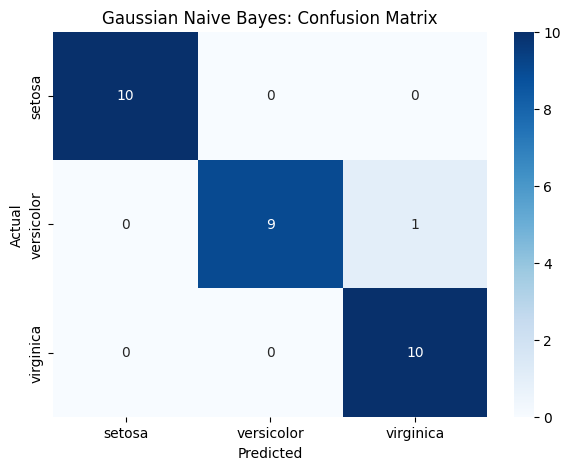

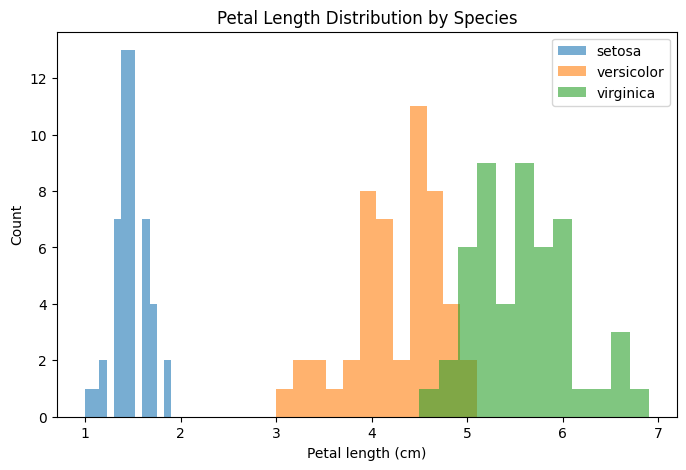

In [7]:
plt.figure(figsize=(7, 5))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues',
            xticklabels=iris.target_names, yticklabels=iris.target_names)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Gaussian Naive Bayes: Confusion Matrix')
plt.show()

plt.figure(figsize=(8, 5))
for i, name in enumerate(iris.target_names):
    plt.hist(X[y == i]['petal length (cm)'], alpha=0.6, label=name, bins=12)
plt.xlabel('Petal length (cm)')
plt.ylabel('Count')
plt.title('Petal Length Distribution by Species')
plt.legend()
plt.show()

## Conclusion
Gaussian Naive Bayes is fast, simple, and needs no tuning or scaling here. It works well because the iris features are roughly normally distributed within each species.